In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [2]:
df = pd.read_csv(r"C:\Users\vmahi1206\Downloads\car_price_dataset.csv")

In [3]:
df.head()

,Car_ID,Brand,Model_Year,Engine_Size,Fuel_Type,Transmission,Mileage,Doors,Owner_Count,Horsepower,Price
0,1,Ford,2023,1.2,Hybrid,Manual,180635,4,3,82,34309.25
1,2,Hyundai,2018,3.2,Electric,Manual,35628,2,4,259,55153.60
2,3,BMW,2008,2.2,Diesel,Manual,74672,3,2,333,41894.40
3,4,Hyundai,2017,2.2,Petrol,Automatic,51246,4,4,381,54046.70
4,5,Hyundai,2012,2.4,Electric,Manual,147233,3,4,290,38010.35


In [4]:
df.tail()

,Car_ID,Brand,Model_Year,Engine_Size,Fuel_Type,Transmission,Mileage,Doors,Owner_Count,Horsepower,Price
1995,1996,Hyundai,2023,4.5,Diesel,Manual,155033,2,3,310,61734.35
1996,1997,Toyota,2023,1.4,Petrol,Manual,25044,2,4,271,48467.80
1997,1998,Hyundai,2022,4.1,Diesel,Manual,104372,4,3,191,55714.40
1998,1999,BMW,2020,4.4,Diesel,Automatic,158047,4,1,186,53222.65
1999,2000,Honda,2012,1.7,Electric,Automatic,19706,3,1,165,40687.70


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Car_ID        2000 non-null   int64  
 1   Brand         2000 non-null   object 
 2   Model_Year    2000 non-null   int64  
 3   Engine_Size   2000 non-null   float64
 4   Fuel_Type     2000 non-null   object 
 5   Transmission  2000 non-null   object 
 6   Mileage       2000 non-null   int64  
 7   Doors         2000 non-null   int64  
 8   Owner_Count   2000 non-null   int64  
 9   Horsepower    2000 non-null   int64  
 10  Price         2000 non-null   float64
dtypes: float64(2), int64(6), object(3)
memory usage: 172.0+ KB


In [6]:
df.isnull().sum()

Car_ID          0
Brand           0
Model_Year      0
Engine_Size     0
Fuel_Type       0
Transmission    0
Mileage         0
Doors           0
Owner_Count     0
Horsepower      0
Price           0
dtype: int64

In [7]:
df = df.drop_duplicates()

In [8]:
df = df.drop(['Car_ID'], axis=1)

In [9]:
df.rename(columns={'Mileage': 'km_driven'},inplace=True)

In [10]:
df

,Brand,Model_Year,Engine_Size,Fuel_Type,Transmission,km_driven,Doors,Owner_Count,Horsepower,Price
0,Ford,2023,1.2,Hybrid,Manual,180635,4,3,82,34309.25
1,Hyundai,2018,3.2,Electric,Manual,35628,2,4,259,55153.60
2,BMW,2008,2.2,Diesel,Manual,74672,3,2,333,41894.40
3,Hyundai,2017,2.2,Petrol,Automatic,51246,4,4,381,54046.70
4,Hyundai,2012,2.4,Electric,Manual,147233,3,4,290,38010.35
...,...,...,...,...,...,...,...,...,...,...
1995,Hyundai,2023,4.5,Diesel,Manual,155033,2,3,310,61734.35
1996,Toyota,2023,1.4,Petrol,Manual,25044,2,4,271,48467.80
1997,Hyundai,2022,4.1,Diesel,Manual,104372,4,3,191,55714.40
1998,BMW,2020,4.4,Diesel,Automatic,158047,4,1,186,53222.65


In [11]:
x = df.drop('Price', axis=1)

In [12]:
y = df['Price']

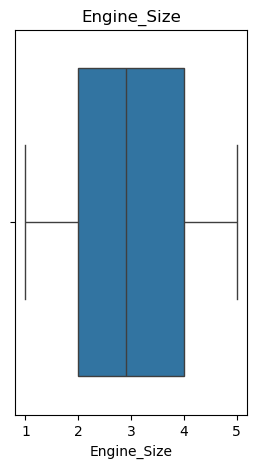

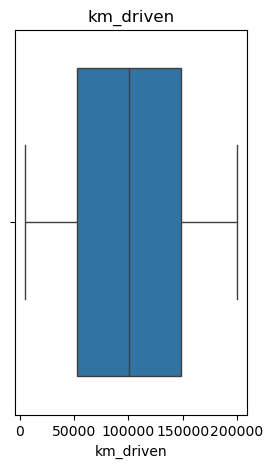

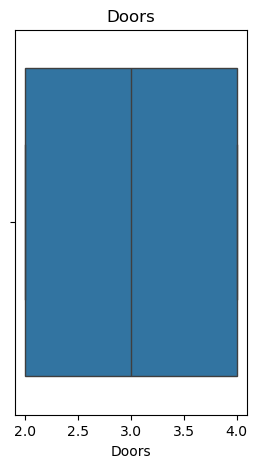

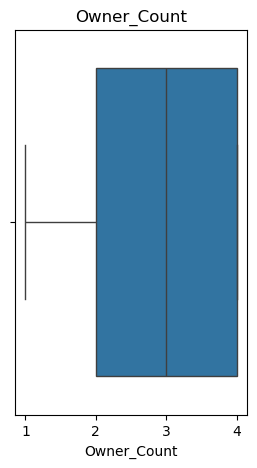

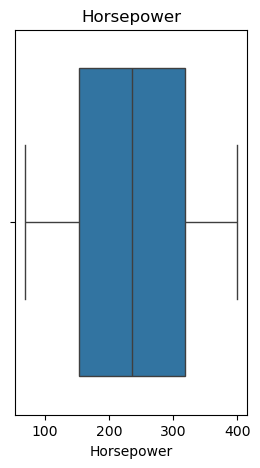

In [13]:
import seaborn as sns
cols = ['Engine_Size','km_driven','Doors','Owner_Count','Horsepower']
for col in cols:
    plt.figure(figsize=(3,5))
    sns.boxplot(x = df[col])
    plt.title(col)
    plt.show()

In [14]:
Categorical_cols = ['Brand', 'Fuel_Type', 'Transmission']

In [15]:
preprocessor = ColumnTransformer(transformers =[('cat', OneHotEncoder(handle_unknown = 'ignore'), Categorical_cols)], remainder = 'passthrough') 

In [16]:
model = Pipeline([('preprocessor',preprocessor),('regressor',LinearRegression())])

In [17]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 40)

model.fit(x_train, y_train)

In [18]:
model.fit(x_train, y_train)

C:\Users\vmahi1206\anaconda3\Lib\site-packages\sklearn\compose\_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Brand', 'Fuel_Type',
                                                   'Transmission'])])),
                ('regressor', LinearRegression())])

In [19]:
y_pred = model.predict(x_test)

In [20]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [21]:
r2_score = r2_score(y_test, y_pred)

In [22]:
mse = mean_squared_error(y_test, y_pred)

In [23]:
mae = mean_absolute_error(y_test, y_pred)

In [24]:
rmse = np.sqrt(mse)

In [25]:
print('R2_score:',r2_score)
print("rmse:",rmse)
print("MAE:",mae)

R2_score: 0.9678773766885381
rmse: 1682.8745495074586
MAE: 1436.7481128233799


In [26]:
results = pd.DataFrame({'Actual_price':y_test,'Predicted_price':y_pred})
print(results)

      Actual_price  Predicted_price
423       35758.60     37983.385424
1495      57129.85     56980.337154
1618      49328.45     48618.778680
1099      55084.10     52841.953251
1307      48207.50     49585.986530
...            ...              ...
739       45146.25     43017.984175
1379      45894.75     44378.488563
837       53557.00     53753.812574
877       51392.40     50201.440703
828       42061.45     41542.615928

[400 rows x 2 columns]


In [27]:
new_car = pd.DataFrame({
    "Brand": ["Toyota"],
    "Model_Year": [2022],
    "Engine_Size": [2.0],
    "Fuel_Type": ["Petrol"],
    "Transmission": ["Automatic"],
    "km_driven": [30000],
    "Doors": [4],
    "Owner_Count": [1],
    "Horsepower": [180]
})
predicted_price = model.predict(new_car)
print('Price:',predicted_price[0])

Price: 50247.266721798806


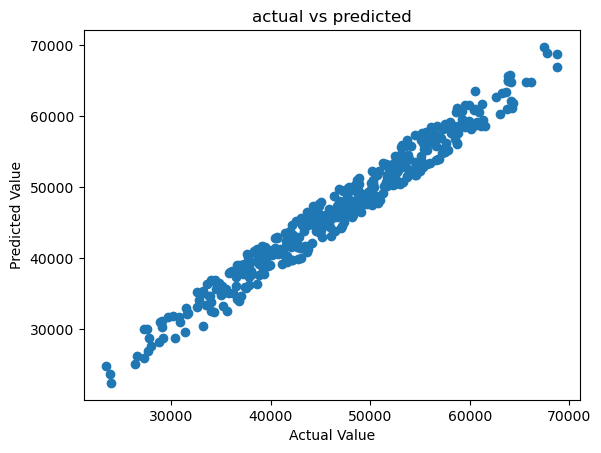

In [28]:
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Value")
plt.ylabel('Predicted Value')
plt.title('actual vs predicted')
plt.show()

In [29]:
import joblib
model = joblib.load("car_price_model.pkl")

joblib.dump(
    model,
    r"C:\Users\vmahi1206\OneDrive\Documents\Car_Price_Prediction_App\car_price_model.pkl"
)

print("Copied Successfully")

Copied Successfully


In [30]:
import os
print(os.listdir())

['.anaconda', '.bash_history', '.conda', '.condarc', '.continuum', '.copilot', '.git', '.gitconfig', '.idlerc', '.ipynb_checkpoints', '.ipython', '.jupyter', '.lesshst', '.local', '.matplotlib', '.spyder-py3', '.streamlit', '.vscode', '.vscode-shared', 'AI_DE_Assignment.ipynb', 'anaconda3', 'anaconda_projects', 'AppData', 'Application Data', 'April2nd', 'car_model.pkl', 'car_price_model.pkl', 'Car_price_project.ipynb', 'columns.pkl', 'Contacts', 'Cookies', 'Data_structures.ipynb', 'Documents', 'Downloads', 'Favorites', 'Functions.ipynb', 'Jedi', 'Links', 'Local Settings', 'Loops.ipynb', 'Mahesh', 'Mahesh1', 'mapper.py', 'Microsoft', 'My Documents', 'Myclass', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{9a33b71b-b0c6-11f0-88a0-9daa8cd95cfc}.TM.blf', 'NTUSER.DAT{9a33b71b-b0c6-11f0-88a0-9daa8cd95cfc}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{9a33b71b-b0c6-11f0-88a0-9daa8cd95cfc}.TMContainer00000000000000000002.regtrans-ms', 'ntuser.ini', 'Num

In [31]:
type(model)

sklearn.pipeline.Pipeline

In [32]:
import sklearn
print(sklearn.__version__)

1.6.1


In [33]:
print(model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Brand', 'Fuel_Type',
                                                   'Transmission'])])),
                ('regressor', LinearRegression())])


In [34]:
df = pd.read_csv(r"C:\Users\vmahi1206\Downloads\car_price_dataset.csv")

print(df["Brand"].unique())
print(df["Fuel_Type"].unique())
print(df["Transmission"].unique())

['Ford' 'Hyundai' 'BMW' 'Honda' 'Tesla' 'Toyota']
['Hybrid' 'Electric' 'Diesel' 'Petrol']
['Manual' 'Automatic']


In [35]:
import sklearn
import joblib

print("sklearn:", sklearn.__version__)

model = joblib.load("car_price_model.pkl")
print(type(model))

sklearn: 1.6.1
<class 'sklearn.pipeline.Pipeline'>


In [36]:
joblib.dump(model, "car_price_model.pkl")

['car_price_model.pkl']

In [37]:
import joblib
import sklearn

print(sklearn.__version__)

loaded_model = joblib.load("car_price_model.pkl")

joblib.dump(
    loaded_model,
    "car_price_model_new.pkl",
    compress=3
)

print("Saved successfully")

1.6.1
Saved successfully


In [38]:
test_model = joblib.load("car_price_model_new.pkl")
print(type(test_model))

<class 'sklearn.pipeline.Pipeline'>


In [39]:
import sys
import sklearn
import joblib

print("Python:", sys.version)
print("Scikit-Learn:", sklearn.__version__)

model = joblib.load("car_price_model.pkl")

print(type(model))
print(model)


Python: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
Scikit-Learn: 1.6.1
<class 'sklearn.pipeline.Pipeline'>
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Brand', 'Fuel_Type',
                                                   'Transmission'])])),
                ('regressor', LinearRegression())])
